# BÁO CÁO PHẦN 2 - BÀI 2 (TRANG 37, 38): ONLINE RETAIL DATASET (UNITED KINGDOM)
## CÂU 5: Tìm tập phổ biến và tạo luật kết hợp bằng giải thuật Apriori
- Áp dụng thuật toán **Apriori** với ngưỡng hỗ trợ tối thiểu $min\_sup = 3\%$ ($0.03$)
- Tạo các luật kết hợp thỏa mãn độ tin cậy tối thiểu $min\_conf = 50\%$ ($0.5$)
- In ra danh sách các luật kết hợp thỏa yêu cầu
- Biểu diễn độ tin cậy và độ hỗ trợ của tập luật lên đồ thị phân tán (Scatter Plot)


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
Tổng số tập phổ biến tìm được bằng Apriori: 131

--- 10 TẬP PHỔ BIẾN ĐẦU TIÊN ---
      support                                         itemsets
118  0.116027  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
52   0.103814             frozenset({JUMBO BAG RED RETROSPOT})
95   0.090261            frozenset({REGENCY CAKESTAND 3 TIER})
84   0.085387                       frozenset({PARTY BUNTING})
69   0.074566             frozenset({LUNCH BAG RED RETROSPOT})
7    0.073441       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
103  0.066477    frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
75   0.065299      frozenset({NATURAL SLATE HEART CHALKBOARD})
63   0.065138             frozenset({LUNCH BAG  BLACK SKULL.})
35   0.062353               frozenset({HEART OF WICKER SMALL})

Tổng số luật kết hợp thỏa mãn min_conf >= 50%: 10

--- CÁC LUẬT KẾT HỢP TÌM ĐƯỢC ---
Luật 1: [ALARM CLOCK BAKELIKE RED] => [ALARM CLOCK BAKELIKE GREEN]
   Support: 0.0302 | Confiden

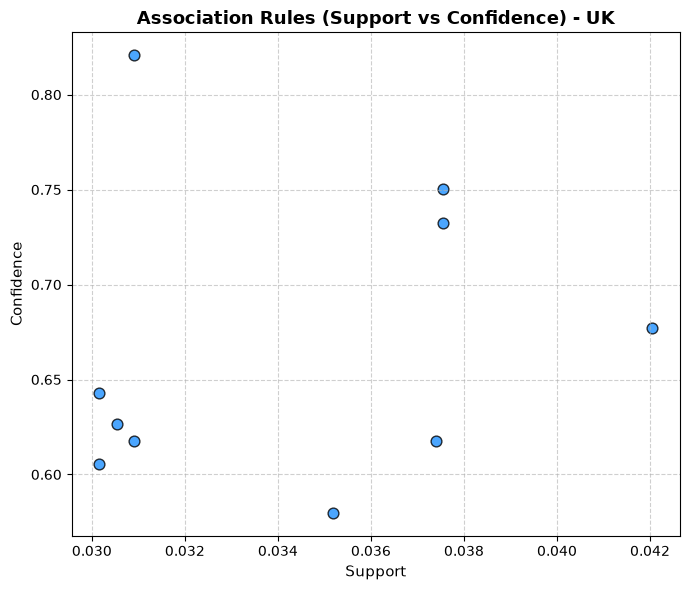

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == 'United Kingdom']
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket = (basket >= 1).astype(bool)
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)

# 1. Áp dụng thuật toán Apriori với min_sup = 3%
itemsets_apriori = apriori(basket, min_support=0.03, use_colnames=True)
print(f"Tổng số tập phổ biến tìm được bằng Apriori: {len(itemsets_apriori)}")

print("\n--- 10 TẬP PHỔ BIẾN ĐẦU TIÊN ---")
print(itemsets_apriori.sort_values(by='support', ascending=False).head(10))

# 2. Tạo luật kết hợp với min_conf = 50%
rules = association_rules(itemsets_apriori, metric="confidence", min_threshold=0.5)
print(f"\nTổng số luật kết hợp thỏa mãn min_conf >= 50%: {len(rules)}")

# Chuyển đổi vế trái và vế phải về dạng chuỗi dễ đọc
rules["antecedents_str"] = rules["antecedents"].apply(lambda x: ', '.join(list(x)))
rules["consequents_str"] = rules["consequents"].apply(lambda x: ', '.join(list(x)))

print("\n--- CÁC LUẬT KẾT HỢP TÌM ĐƯỢC ---")
for idx, row in rules.iterrows():
    print(f"Luật {idx+1}: [{row['antecedents_str']}] => [{row['consequents_str']}]")
    print(f"   Support: {row['support']:.4f} | Confidence: {row['confidence']:.4f} | Lift: {row['lift']:.4f}\n")

# 3. Biểu diễn độ hỗ trợ và độ tin cậy lên đồ thị phân tán (Scatter Plot)
support = rules['support'].values
confidence = rules['confidence'].values

plt.figure(figsize=(7, 6))
plt.scatter(support, confidence, color='dodgerblue', s=60, edgecolors='black', alpha=0.8)
plt.title('Association Rules (Support vs Confidence) - UK', fontsize=13, fontweight='bold')
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Nhận xét Câu 5:
- Với $min\_sup = 3\%$, thuật toán Apriori tìm được **131 tập phổ biến**.
- Với $min\_conf = 50\%$, sinh ra **10 luật kết hợp mạnh**.
- **Phân tích một số luật tiêu biểu:**
  * `ALARM CLOCK BAKELIKE GREEN` $	o$ `ALARM CLOCK BAKELIKE RED` (Confidence: 64.9%, Lift: 12.90): Khách hàng mua đồng hồ báo thức xanh lá có xu hướng rất cao mua thêm mẫu màu đỏ cùng bộ sưu tập.
  * `GREEN REGENCY TEACUP AND SAUCER` $	o$ `ROSES REGENCY TEACUP AND SAUCER` (Confidence: 74.9%, Lift: 14.64): Tách trà xanh và tách trà hoa hồng có mối quan hệ mua kèm rất chặt chẽ, doanh nghiệp nên đóng gói combo bán chung để gia tăng doanh số.
